In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from scipy import stats
from modularRNN.analysis import (
    load_and_pool_sessions,
    decode_module_specificity,
    plot_rt_distributions,
    plot_rt_vs_contrast,
    plot_module_specificity,
    add_outcome_and_congruency_columns,
)
from modularRNN.generate_data import run_and_save_multi_session, load_checkpoint
from modularRNN.generators import SessionPlanGenerator
from modularRNN.conf.config import Config
import torch
from glob import glob
from matplotlib import pyplot as plt
import seaborn as sns
import psychofit as psy
from modularRNN.plotting import (
    plot_psychometric,
    plot_population_psychometric_by_block_pooled,
    pretty_plot,
    reaction_time_plots,
)
import warnings

warnings.filterwarnings("ignore")

In [2]:
%load_ext autoreload
%autoreload 2

In [5]:
ckpt_path = "../model/checkpoints/rqqt5iy1/ckpt_20000.pt"
device = "cpu"
model, train_cfg = load_checkpoint(ckpt_path, device)

Loaded checkpoint from step 20000


In [6]:
path = glob("../data/multi_session_mit_ak/*")

In [7]:
meta_df, hidden_visual, hidden_motor = load_and_pool_sessions(path)
trace_len = meta_df["trace_len"].values

In [8]:
meta_df = add_outcome_and_congruency_columns(meta_df)

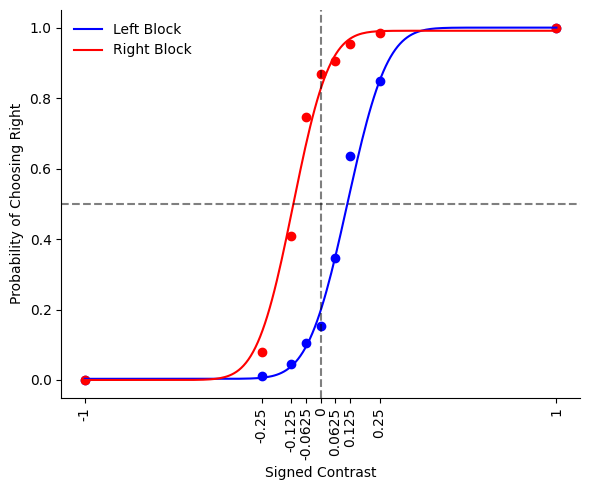

In [9]:
params, fig = plot_population_psychometric_by_block_pooled(meta_df)

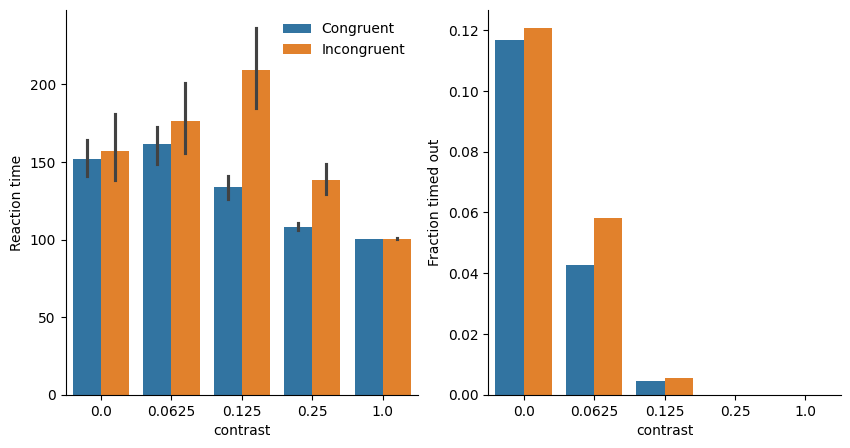

In [10]:
reaction_time_plots(meta_df, train_cfg.env.T_max)

In [11]:
decode_results = decode_module_specificity(
    hidden_visual,
    hidden_motor,
    meta_df,
    trace_len,
    n_shuffles=100,
    epoch_fracs=(0, 0.2, 0.5, 0.8, 1),
)

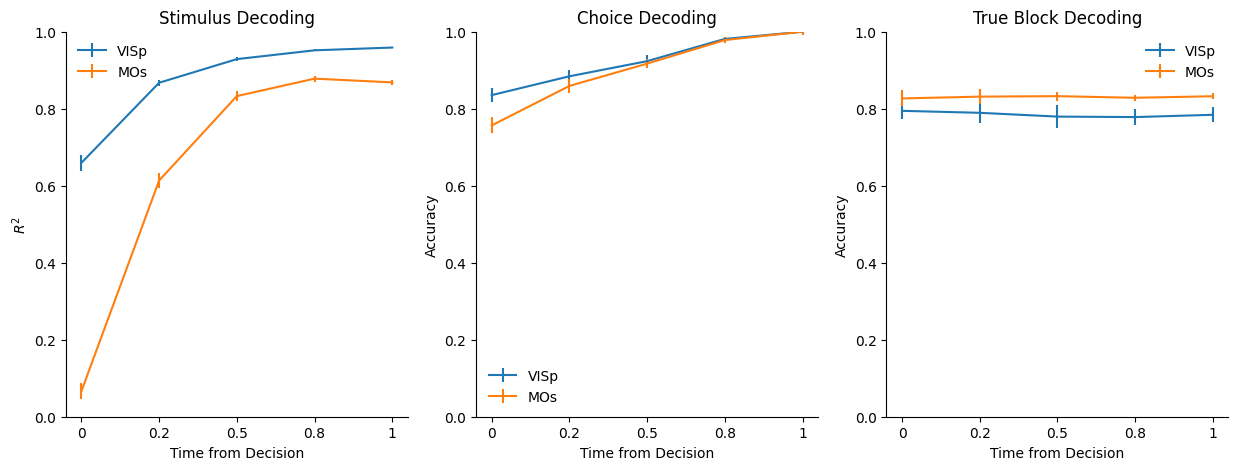

In [12]:
pretty_plot(decode_results)

In [13]:
print(train_cfg.model.n_fb)  # must be 2
print(train_cfg.env.kappa_kernel)

2
0.5


In [14]:
print(model.W_in_fb_visp.shape)  # should be (n_visp, 2), not (n_visp, 1)
print(model.W_in_fb_mos.shape)

torch.Size([32, 2])
torch.Size([32, 2])


In [ ]:
kernel_term = (
    train_cfg.env.kappa_kernel * meta_df["action_kernel"]
)  # from stored data, raw trace * kappa
print(kernel_term.abs().mean(), kernel_term.abs().std())
# 0.29735693 0.15021949
print(meta_df["action_kernel"].abs().mean(), meta_df["action_kernel"].abs().std())
# 0.59471387 0.30043897

0.29735693 0.15021949
0.59471387 0.30043897


In [22]:
def repeat_rate_by_contrast(meta_df):
    d = meta_df.copy()
    d["has_prev_choice"] = d["has_prev_choice"].astype(bool)
    d["repeated"] = d["choice"] == d["prev_model_choice"]
    return d[d["has_prev_choice"]].groupby("contrast")["repeated"].mean()


print(repeat_rate_by_contrast(meta_df))

contrast
0.0000    0.899033
0.0625    0.848162
0.1250    0.795476
0.2500    0.705295
1.0000    0.640976
Name: repeated, dtype: float64


In [23]:
d = meta_df[(meta_df["contrast"] == 0.0) & (meta_df["committed"])]
d.groupby("congruent")["correct"].mean()

congruent
False    0.314879
True     0.854086
Name: correct, dtype: float64

In [24]:
d = meta_df[(meta_df["contrast"] == 0.0)]
d.groupby("congruent")["correct"].mean()

congruent
False    0.258523
True     0.754296
Name: correct, dtype: float64

In [52]:
def repeat_rate_by_contrast_and_congruency(meta_df):
    d = meta_df.copy()
    d["has_prev_choice"] = d["has_prev_choice"].astype(bool)
    d["repeated"] = d["choice"] == d["prev_model_choice"]

    is_biased = d["block_bias"] != 0.5
    block_right = d["block_bias"] > 0.5
    stim_right = d["stim_side"] > 0
    d["congruent"] = (block_right == stim_right) & is_biased
    d["incongruent"] = (~d["congruent"]) & is_biased
    d["congruency"] = np.where(
        d["congruent"], "congruent", np.where(d["incongruent"], "incongruent", None)
    )

    d = d[d["has_prev_choice"] & d["congruency"].notna()]

    return (
        d.groupby(["contrast", "congruency"])["repeated"]
        .agg(["mean", "size"])
        .rename(columns={"mean": "repeat_rate", "size": "n"})
    )


def plot_repeat_rate_by_contrast_and_congruency(result_df):
    result_df = result_df.reset_index()
    fig, ax = plt.subplots(figsize=(6, 4.5))
    colors = {"congruent": "tab:blue", "incongruent": "tab:orange"}

    for cond, color in colors.items():
        sub = result_df[result_df["congruency"] == cond].sort_values("contrast")
        ax.plot(
            sub["contrast"], sub["repeat_rate"], marker="o", color=color, label=cond
        )
    ax.set_xlabel("contrast")
    ax.set_ylabel("repeat rate")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=9)
    fig.tight_layout()
    ax.set_title("Repeats")
    ax.set_xticks(
        result_df["contrast"].unique(),
        labels=result_df["contrast"].unique(),
        rotation=90,
    )
    sns.despine()
    return fig

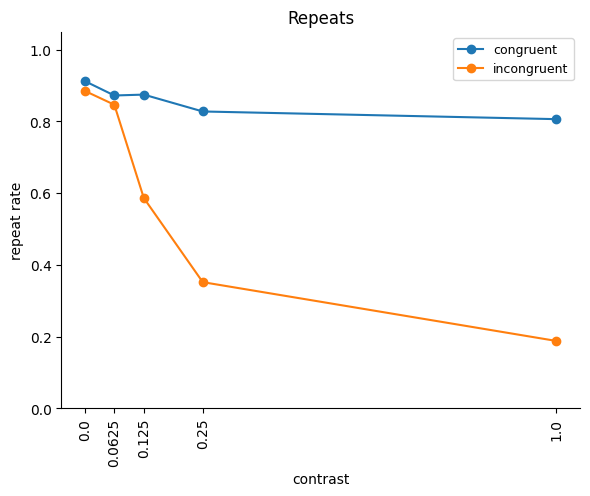

In [53]:
result_df = repeat_rate_by_contrast_and_congruency(meta_df)
fig = plot_repeat_rate_by_contrast_and_congruency(result_df)

In [37]:
result_df

repeat_rate    n
contrast congruency                   
0.0000   congruent       0.912371  582
         incongruent     0.885057  174
0.0625   congruent       0.872340  658
         incongruent     0.846561  189
0.1250   congruent       0.874816  679
         incongruent     0.586592  179
0.2500   congruent       0.827795  662
         incongruent     0.352113  142
1.0000   congruent       0.806402  656
         incongruent     0.188172  186